# c10 · Step 10: Decision threshold (ROC), on val

Rule fixed in c2, before any model existed: **predict "tumour" when P(tumour) = 1 - P(no_tumor) > t, with t the
highest cutoff that gives tumour sensitivity ≥ 0.98 on clean val.** If it says tumour, the tumour type is the most
likely of the three tumour classes. For comparison: argmax (no threshold), Youden's J, and a 10:1 cost ratio
(a missed tumour counts 10x a false alarm).

The **test set is not touched** in this run. The last cell evaluates it with everything frozen, but it is switched
off (`RUN_TEST = False`) so that the user decides when the single test evaluation happens.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
sys.path.insert(0, ".")
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score, confusion_matrix
from lib.data import ARTIFACTS, CLASSES, NO_TUMOR, SEED
from lib.train import RESULTS
from lib.evaluation import wilson, tumor_score
FINAL = json.loads((ARTIFACTS / "final.json").read_text())
d = np.load(RESULTS / "c9" / f"final_s{SEED}_val.npz"); y, prob = d["y"], d["prob"]
is_tumor = y != NO_TUMOR; score = tumor_score(prob)
print(f"clean val: {is_tumor.sum()} tumour, {(~is_tumor).sum()} no-tumour images")

clean val: 736 tumour, 96 no-tumour images


## 1. ROC curve and the candidate cutoffs

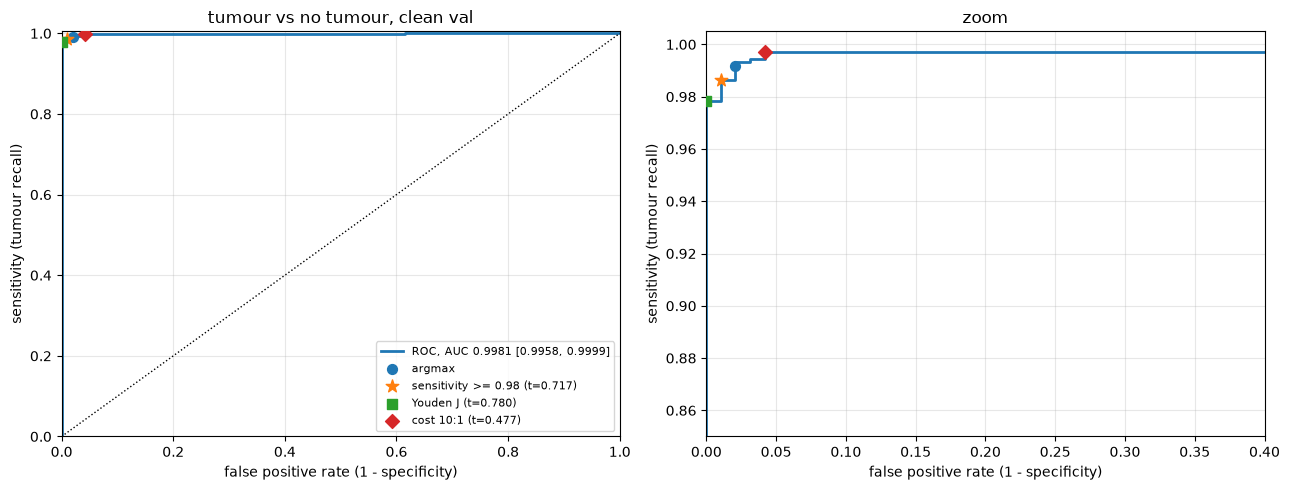

In [2]:
fpr, tpr, thr = roc_curve(is_tumor, score)
auc = roc_auc_score(is_tumor, score)
rng = np.random.default_rng(SEED)
boot = [roc_auc_score(is_tumor[i], score[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(2000)) if is_tumor[i].any() and (~is_tumor[i]).any()]
lo, hi = np.quantile(boot, [0.025, 0.975])
TARGET = 0.98
i_target = np.where(tpr >= TARGET)[0][0]                      # highest threshold reaching the target
i_youden = np.argmax(tpr - fpr)
P_t, P_n = is_tumor.mean(), 1 - is_tumor.mean()
cost = 10 * (1 - tpr) * P_t + 1 * fpr * P_n
i_cost = np.argmin(cost)
pred_arg_tumor = prob.argmax(1) != NO_TUMOR
arg_tpr, arg_fpr = pred_arg_tumor[is_tumor].mean(), pred_arg_tumor[~is_tumor].mean()
cuts = {"argmax": (None, arg_tpr, arg_fpr), f"sensitivity >= {TARGET}": (thr[i_target], tpr[i_target], fpr[i_target]),
        "Youden J": (thr[i_youden], tpr[i_youden], fpr[i_youden]), "cost 10:1": (thr[i_cost], tpr[i_cost], fpr[i_cost])}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, lim in zip(ax, [(0, 1), (0, 0.4)]):
    a.plot(fpr, tpr, lw=2, label=f"ROC, AUC {auc:.4f} [{lo:.4f}, {hi:.4f}]")
    a.plot([0, 1], [0, 1], "k:", lw=1)
    for (k, (t, tp, fp)), mk in zip(cuts.items(), ["o", "*", "s", "D"]):
        a.scatter(fp, tp, s=90 if mk == "*" else 50, marker=mk, zorder=3, label=f"{k}" + (f" (t={t:.3f})" if t is not None else ""))
    a.set(xlim=lim, ylim=(lim[0] * 0 + (0.85 if lim[1] < 1 else 0), 1.005), xlabel="false positive rate (1 - specificity)",
          ylabel="sensitivity (tumour recall)"); a.grid(alpha=0.3)
ax[0].set_title("tumour vs no tumour, clean val"); ax[1].set_title("zoom"); ax[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

In [3]:
rows = {}
for k, (t, tp, fp) in cuts.items():
    pt = pred_arg_tumor if t is None else score > t
    kt, nt = int((pt & is_tumor).sum()), int(is_tumor.sum()); kn, nn = int((~pt & ~is_tumor).sum()), int((~is_tumor).sum())
    s_lo, s_hi = wilson(kt, nt); p_lo, p_hi = wilson(kn, nn)
    rows[k] = {"threshold": t, "sensitivity": kt / nt, "sens 95% CI": f"[{s_lo:.3f}, {s_hi:.3f}]", "missed tumours": nt - kt,
               "specificity": kn / nn, "spec 95% CI": f"[{p_lo:.3f}, {p_hi:.3f}]", "false alarms": nn - kn}
display(pd.DataFrame(rows).T)

,threshold,sensitivity,sens 95% CI,missed tumours,specificity,spec 95% CI,false alarms
argmax,None,0.991848,"[0.982, 0.996]",6,0.979167,"[0.927, 0.994]",2
sensitivity >= 0.98,0.717461,0.985054,"[0.973, 0.992]",11,0.989583,"[0.943, 0.998]",1
Youden J,0.780391,0.976902,"[0.963, 0.986]",17,1.0,"[0.962, 1.000]",0
cost 10:1,0.477306,0.995924,"[0.988, 0.999]",3,0.958333,"[0.898, 0.984]",4


_TODO roc_

## 2. What the chosen rule does to the 4-class predictions

In [4]:
T_STAR = float(thr[i_target])
def predict_with_threshold(prob, t):
    p = prob.copy(); p[:, NO_TUMOR] = -1                   # best tumour class
    tumour_type = p.argmax(1)
    return np.where(tumor_score(prob) > t, tumour_type, NO_TUMOR)
pred_t = predict_with_threshold(prob, T_STAR)
for name, pr in [("argmax", prob.argmax(1)), (f"threshold {T_STAR:.3f}", pred_t)]:
    cm = confusion_matrix(y, pr, labels=range(4))
    print(f"{name}: balanced accuracy {balanced_accuracy_score(y, pr):.4f}")
    print(pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]), "\n")
_ = (ARTIFACTS / "threshold.json").write_text(json.dumps({"rule": f"tumour sensitivity >= {TARGET} on clean val",
                                                           "threshold": T_STAR, "val_auc": auc}))

argmax: balanced accuracy 0.9678
                 pred glioma  pred meningioma  pred no_tumor  pred pituitary
true glioma              303                6              2               1
true meningioma            9              201              4               2
true no_tumor              2                0             94               0
true pituitary             1                1              0             206 

threshold 0.717: balanced accuracy 0.9668
                 pred glioma  pred meningioma  pred no_tumor  pred pituitary
true glioma              300                6              5               1
true meningioma            9              201              4               2
true no_tumor              1                0             95               0
true pituitary             0                1              2             205 



_TODO effect_

## 3. Test set: one evaluation, everything frozen (switched off)
Model = `final.json` checkpoint (seed 1738), threshold = `threshold.json`. Reports the official test set (889) and
the clean test set (833, without the train copies found in c1).

In [5]:
RUN_TEST = False
if RUN_TEST:
    from dataclasses import fields
    from lib.train import Config, build_model, prepare_data, predict, DEVICE
    from lib.data import load_split, GPUSplit
    from lib.evaluation import evaluate
    cfg = Config(**{f.name: (tuple(FINAL["config"][f.name]) if isinstance(FINAL["config"][f.name], list) else FINAL["config"][f.name])
                    for f in fields(Config)})
    train, _ = prepare_data(cfg)
    net = build_model(cfg, train.X.shape[1]).to(DEVICE)
    net.load_state_dict(torch.load(FINAL["checkpoint"], map_location=DEVICE))
    for clean in [False, True]:
        te = GPUSplit(load_split("test", cfg.mode, cfg.resize, cfg.size, clean=clean), DEVICE, train.mean, train.std,
                      cfg.normalize == "per_image")
        p = predict(net, te); yt = te.y.cpu().numpy(); m = evaluate(yt, p)
        pt = predict_with_threshold(p, T_STAR); tum = yt != NO_TUMOR
        print(f"{'clean' if clean else 'official'} test (n={len(yt)}): bal. acc {m['bal_acc']:.4f}, macro-F1 {m['macro_f1']:.4f}, "
              f"tumour AUC {m['tumor_auc']:.4f} | threshold rule: sensitivity {(pt[tum] != NO_TUMOR).mean():.4f}, "
              f"specificity {(pt[~tum] == NO_TUMOR).mean():.4f}")
else:
    print("Test set not evaluated (RUN_TEST = False).")

Test set not evaluated (RUN_TEST = False).
